# Lab 05: How to manage what an agent sees

**Notebook 2 of 2: context and skills at the Chinook desk**

## Goal

Put skills to work on a real job: the support desk of the Chinook music shop, where a rep asks what to do about a
customer and the answer depends on the shop's rules. The rules are written as three Agent Skills. We give the desk
agent their names and descriptions, two tools to load them, and its usual database lookups. The moment to watch
for: from three one-line descriptions the model asks for the refund skill, reads it, and then asks on its own for
the reference file that skill points to. A question that needs no rule loads no skill at all. At the end we set
this agent beside one that carries every rule in its system prompt, and count what each sends.

## What you will learn

- How to build the skill list of an agent from the `SKILL.md` folders on disk.
- How to offer skills as two tools beside an agent's lookup tools, and follow one run through the three levels.
- How to read from a run which questions load a skill and which do not.
- How to compare a prompt that lists skills with one that carries every rule: input tokens per call and per
  question, and what each one cannot do.

## From the playground to the desk

In notebook 1 a model answered a house-sitter's questions from our notes. Four ideas carry over:

- `usage.prompt_tokens` counts everything a call sent to the model. The model keeps nothing between calls, so a
  long system prompt is sent, and paid for, on every call.
- A **skill** is a folder with a `SKILL.md`: a `name` and a `description` at the top (the frontmatter), the
  instructions below them (the body), and reference files beside it.
- A skill loads in **three levels**: the name and description of every skill in every call; one body when the
  model asks for it; a reference file when the body points to it.
- The model asks for a tool and our code runs it. A small loop repeats that until the model answers.

Now we take it seriously. A rep repeats these answers to a customer, and the rules are about money. This notebook
restates everything it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import json
import os
import sqlite3
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


The client, as in notebook 1: Chat Completions, a 60-second limit on every request, and
`reasoning_effort=EFFORT or omit` on every call (the effort from `models.env`, left out when that setting is
empty).

In [2]:
from openai import OpenAI, omit

client = OpenAI(timeout=60, max_retries=2)

---

## Part A: Read the desk's rules as three skills

The Chinook shop sells music: CDs, vinyl records and digital albums. Its support reps answer customers who were
charged twice, received a cracked record or want to change their email. What a rep may offer in each case is
written down, and someone has already written three of those procedures as skills, in the folder `skills/` beside
this notebook.

### The folder

In [3]:
LAB = ROOT / "05_Context_And_Skills"
SKILLS_DIR = LAB / "skills"

for path in sorted(SKILLS_DIR.rglob("*")):
    print(path.relative_to(SKILLS_DIR))

account-changes
account-changes/SKILL.md
damaged-media
damaged-media/SKILL.md
refund-requests
refund-requests/SKILL.md
refund-requests/references
refund-requests/references/duplicate-charges.md


Three skill folders, each with a `SKILL.md`. One of them, `refund-requests`, also has a reference file,
`references/duplicate-charges.md`. We print that skill's `SKILL.md` as it is on disk.

In [4]:
print((SKILLS_DIR / "refund-requests" / "SKILL.md").read_text())

---
name: refund-requests
description: Decide whether a Chinook order is refunded, which invoice and how much, and how long the money takes to arrive. Use when a customer asks for their money back, was charged twice, wants a partial refund for defective tracks, or regrets a digital purchase.
---

# Refund requests

Follow these steps for any request to give money back.

1. **Find the invoice.** Ask for the invoice number if the customer did not give it. Never guess one.
2. **Check the reason against the rules:**
   - A customer who changed their mind about a digital purchase gets no refund.
   - When only some tracks on a multi-disc set are defective, refund those tracks only (a partial refund).
   - A disc or record that arrived damaged is replaced first, not refunded: use the `damaged-media` skill.
   - **Charged twice:** read `references/duplicate-charges.md` before you answer. It says which invoice to refund.
3. **Say where the money goes and when.** Refunds go back to the original

Read it the way the model will meet it:

- **The frontmatter** (between the `---` lines) has the `name` and a `description` in two sentences: what the
  skill decides, and when to use it ("Use when a customer asks for their money back, was charged twice, ...").
- **The body** is four numbered steps for any refund.
- **Step 2, last line:** for a customer who was charged twice, the body does not give the rule. It says to read
  `references/duplicate-charges.md` first. That is level 3: a detail kept out of the body because most refund
  questions do not need it.

### The skill list, built from the folders

We read every `SKILL.md` into a dictionary, as in notebook 1. `split("---", 2)` cuts the file into the part before
the first `---` (empty), the frontmatter and the body, and `yaml.safe_load` turns the frontmatter into a
dictionary. The list is then one line per skill.

In [5]:
import yaml

SKILLS = {}
for path in sorted(SKILLS_DIR.glob("*/SKILL.md")):
    before, frontmatter, body = path.read_text().split("---", 2)
    meta = yaml.safe_load(frontmatter)
    SKILLS[meta["name"]] = {"description": meta["description"], "body": body.strip(), "folder": path.parent}

skill_list = "\n".join(f"- {name}: {skill['description']}" for name, skill in SKILLS.items())
print(skill_list)

- account-changes: Change the email on a customer's account or delete the account, within the once-a-year email rule, and say what deletion keeps. Use when a customer asks to update their email or login, or to close or delete their account.
- damaged-media: Handle a CD or vinyl record that arrived cracked, warped or will not play, with a free replacement, the photo we need, and when to refund instead. Use when a customer reports physical damage to a disc, record or boxed set.
- refund-requests: Decide whether a Chinook order is refunded, which invoice and how much, and how long the money takes to arrive. Use when a customer asks for their money back, was charged twice, wants a partial refund for defective tracks, or regrets a digital purchase.


Three lines. This is level 1, and it is everything the model is sent about the rules before it asks for more:
three names, and for each one what it covers and when to use it.

### The two functions that load the rest

`load_skill(name)` returns a body (level 2). `read_skill_file(skill, path)` returns one file inside a skill's
folder (level 3).

⚠️ The `path` is written by the model, so `read_skill_file` checks it. `resolve()` works out the full path with
every `..` removed, and the function refuses a file whose parent folders do not include the skill's own folder.
Without that check, a path such as `../../../.env` would hand the model your API key.

In [6]:
def load_skill(name):
    # Level 2: the body of one SKILL.md
    return SKILLS[name]["body"]


def read_skill_file(skill, path):
    # Level 3: one file inside the skill's folder, and nothing outside it
    folder = SKILLS[skill]["folder"].resolve()
    target = (folder / path).resolve()
    if folder not in target.parents or not target.is_file():
        return "No such file in this skill."
    return target.read_text()


print(load_skill("damaged-media"))
print("-----")
print(read_skill_file("damaged-media", "../account-changes/SKILL.md"))

# Damaged media

1. **Ask for a photo** of the damage. Damaged media that will not play is urgent: it jumps the support queue.
2. **Replace it at no charge.** The customer keeps the damaged copy until the replacement arrives, then recycles it.
   We do not ask for it back.
3. **The same title damaged twice:** offer a refund instead of a third copy. Use the `refund-requests` skill for the
   refund itself.
4. **Ordinary wear is not damage:** wear from ordinary play (scratches, a sleeve warped by sunlight) is not a defect.
   Manufacturing defects are covered for 90 days from the invoice date.

Your reply says what we send, what we need from the customer, and what happens if it happens again.
-----
No such file in this skill.


The first call printed the body of `damaged-media`: ask for a photo, replace at no charge, refund on the second
damaged copy. The second call asked for a file in another skill's folder through `..`, and got the refusal.

**Checkpoint A.** The folder listing shows three skills and one reference file. `skill_list` has three lines.
`load_skill("damaged-media")` prints four numbered steps, and the path that leaves the folder returns
`No such file in this skill.`

---

## Part B: Watch the model go from the list to a skill to its reference file

A rep types:

> A customer was charged twice for the same album on the same day. What do we do?

The answer is in the reference file, two levels down. Nothing in the system prompt will say so. We want to see
whether the model gets there from the list alone, so we go one call at a time.

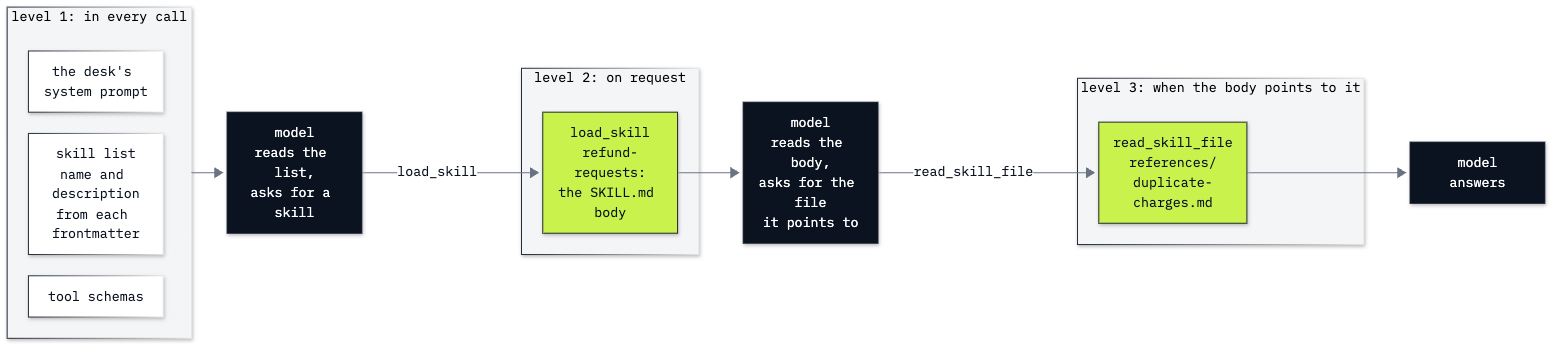

In [7]:
from IPython.display import Image

Image(str(LAB / "resources" / "lab05_three_levels.png"), width=760)

The picture is the plan: the list in every call, the body when the model asks for the skill, the reference when
the body sends the model to it. The dark boxes are the model's turns, the lime boxes what our code sends back.

### The tools and the system prompt

Two tool schemas, one per function, in the shape notebook 1 used:

- `name` is what the model writes to ask for the tool, and `description` says what the tool does.
- `parameters` lists the arguments, and `required` names those that must be present.
- `enum` limits the skill argument of each tool (`name` in `load_skill`, `skill` in `read_skill_file`) to the three
  skill names, so the model cannot ask for a skill that does not exist.
- `additionalProperties: False` and `strict: True` make the model's arguments match the schema exactly.
- `path` is free text, which is why `read_skill_file` checks it.

In [8]:
skill_tools = [
    {
        "type": "function",
        "function": {
            "name": "load_skill",
            "description": "Load the full steps of one skill from the skill list.",
            "parameters": {
                "type": "object",
                "properties": {"name": {"type": "string", "enum": list(SKILLS)}},
                "required": ["name"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
    {
        "type": "function",
        "function": {
            "name": "read_skill_file",
            "description": "Read a file inside a skill's folder, when the skill's steps point to it.",
            "parameters": {
                "type": "object",
                "properties": {
                    "skill": {"type": "string", "enum": list(SKILLS)},
                    "path": {"type": "string", "description": "Path inside the skill folder"},
                },
                "required": ["skill", "path"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
]

The system prompt is the **thin prompt**: who the agent works for, how to use the skills, and the list. It holds
no rule of the shop.

In [9]:
BASE = (
    "You help the support reps of the Chinook music shop. Look up every customer fact with the tools; "
    "never answer from memory. Answer in two or three sentences."
)

THIN = (
    BASE
    + " The shop's rules are kept as skills. Each skill below holds the steps for one kind of request. "
    + "Before you answer a question about the shop's rules, load the skill that covers it with load_skill, "
    + "and read a file inside it with read_skill_file when its steps tell you to. "
    + "If no skill covers the question, say that the rules you have do not cover it.\n\n"
    + "Skills:\n"
    + skill_list
)

print(len(THIN), "characters")

1267 characters


### Call 1: the model reads the list

We send the question and print the input tokens, the reply's text and the tools the model asked for.

In [10]:
DUPLICATE = "A customer was charged twice for the same album on the same day. What do we do?"

messages = [
    {"role": "system", "content": THIN},
    {"role": "user", "content": DUPLICATE},
]

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=skill_tools, reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("input tokens:", response.usage.prompt_tokens)
print("text:", reply.content)
for call in reply.tool_calls:
    print("asked for:", call.function.name, call.function.arguments)

input tokens: 499
text: None
asked for: load_skill {"name":"refund-requests"}


499 input tokens, no text, and one request: `load_skill` with `{"name":"refund-requests"}`. Of the three descriptions, that is the one that says "was charged twice". The model chose it from the list, which is all it has read so far.

The model has only asked. `run_calls` does our side of the work: it adds the model's request to the conversation,
runs each tool the model asked for, and adds each result as a `tool` message with the request's id.
`FUNCTIONS` maps a tool's name to the Python function that runs it.

In [11]:
FUNCTIONS = {"load_skill": load_skill, "read_skill_file": read_skill_file}


def run_calls(reply, messages):
    # Add the model's request, then run each tool it asked for and add each result
    messages.append(reply)
    for call in reply.tool_calls:
        arguments = json.loads(call.function.arguments)
        print("   the model asked for:", call.function.name, arguments)
        result = FUNCTIONS[call.function.name](**arguments)
        if not isinstance(result, str):
            result = json.dumps(result, ensure_ascii=False)
        messages.append({"role": "tool", "tool_call_id": call.id, "content": result})


run_calls(reply, messages)

   the model asked for: load_skill {'name': 'refund-requests'}


A tool message carries text, so `run_calls` turns any result that is not a string into JSON. The two skill
functions already return strings; Part C adds lookups that return dictionaries.

### Call 2: the model reads the body

The conversation now ends with the body of `refund-requests`. Same call, longer list of messages.

In [12]:
response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=skill_tools, reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("input tokens:", response.usage.prompt_tokens)
print("text:", reply.content)
for call in reply.tool_calls or []:
    print("asked for:", call.function.name, call.function.arguments)

input tokens: 750
text: None
asked for: read_skill_file {"skill":"refund-requests","path":"references/duplicate-charges.md"}


750 input tokens now: the first call's 499 again, plus the model's request and the refund steps. Again no text. The model read step 2, found the line about customers who were charged twice, and asked for the file that line names: `read_skill_file` with `references/duplicate-charges.md`.

### Call 3: the model reads the reference and answers

In [13]:
run_calls(reply, messages)

response = client.chat.completions.create(
    model=MODEL, messages=messages, tools=skill_tools, reasoning_effort=EFFORT or omit
)
reply = response.choices[0].message

print("input tokens:", response.usage.prompt_tokens)
print("asked for:", reply.tool_calls)
print(reply.content)

   the model asked for: read_skill_file {'skill': 'refund-requests', 'path': 'references/duplicate-charges.md'}


input tokens: 1003
asked for: None
For two invoices for the same album on the same day, refund the later invoice (the higher invoice number) in full, and include both invoice numbers in the refund request. Please provide both invoice numbers and amounts so we can confirm they match; if they do, the refund goes to the original payment method within 5–10 business days after approval, with a decision within 3 business days of your first reply.


1,003 input tokens, no tool call (`None`), and an answer: refund the later invoice, the one with the higher number, in full; put both invoice numbers on the refund request; the money goes back to the original payment method 5 to 10 business days after approval. Those are the reference file's steps. The reply also asks for the two invoice numbers and amounts, which the rep's question did not give.

Put the three calls side by side:

| Call | Input tokens | What the model had read | What it did |
|---|---|---|---|
| 1 | 499 | the list: three names and descriptions | asked for `refund-requests` |
| 2 | 750 | the list and the refund steps | asked for `references/duplicate-charges.md` |
| 3 | 1,003 | the list, the steps and the reference | answered |

**Key lesson:** we never told the model that duplicate charges have their own file. The description sent it to
the skill, and a line in the skill sent it to the file. Each level is written to say when the next one is needed,
and that writing is the work of making a skill.

**Notice** the token counts too. They grow from call to call, because what was loaded stays in the conversation
and is sent again on every later call.

**Checkpoint B.** Call 1 has no text and asks for `load_skill` with `refund-requests`. Call 2 asks for
`read_skill_file` with `references/duplicate-charges.md`. Call 3 answers: refund the later invoice in full and
attach both invoice numbers.

---

## Part C: Ask a question that needs a lookup and no skill

A desk agent does more than quote rules. Most questions are about one customer, and the answer is in the shop's
database. This part gives the agent its lookups beside the skills, and asks a question where no skill should
load.

### The three lookups

The shop's data is `data/chinook.db`, a SQLite file with the customers, their invoices and the support reps who
look after them. Three small functions read it:

- `find_customer(name)` finds a customer by full name and returns their `customer_id`.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

`mode=ro` opens the database **read-only**, so no tool can change the shop's data.

In [14]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list[dict]:
    """Find a shop customer by full name. Returns a list of matches with their customer_id.

    Args:
        name: First and last name, for example 'Ana Silva'.
    """
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We call them ourselves first, so we know the right answer before the model is involved.

In [15]:
customer = find_customer("Helena Holý")[0]
print(customer)
print(get_invoices(customer["customer_id"]))
print(get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
{'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
{'customer_id': 6, 'support_rep': 'Steve Johnson'}


Helena Holý is customer 6, with 7 invoices that add up to \$49.62, and her support rep is Steve Johnson.

### The lookups as tools, beside the skills

Each lookup gets a schema of the same shape as the skill tools: a name, a description copied by hand from the
function's docstring, and its one argument. The three schemas differ only in name, description and argument: a
name string for `find_customer`, an `integer` id for the other two. `ALL_TOOLS` is the five schemas together, and we add the three functions to
`FUNCTIONS` so that `run_calls` can run them.

In [16]:
lookup_tools = [
    {
        "type": "function",
        "function": {
            "name": "find_customer",
            "description": "Find a shop customer by full name. Returns a list of matches with their customer_id.",
            "parameters": {
                "type": "object",
                "properties": {"name": {"type": "string", "description": "First and last name"}},
                "required": ["name"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
    {
        "type": "function",
        "function": {
            "name": "get_invoices",
            "description": "Count a customer's invoices and add up their total in US dollars.",
            "parameters": {
                "type": "object",
                "properties": {"customer_id": {"type": "integer"}},
                "required": ["customer_id"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
    {
        "type": "function",
        "function": {
            "name": "get_support_rep",
            "description": "Name the support rep who looks after a customer.",
            "parameters": {
                "type": "object",
                "properties": {"customer_id": {"type": "integer"}},
                "required": ["customer_id"],
                "additionalProperties": False,
            },
            "strict": True,
        },
    },
]

ALL_TOOLS = lookup_tools + skill_tools
FUNCTIONS.update({"find_customer": find_customer, "get_invoices": get_invoices, "get_support_rep": get_support_rep})

print([tool["function"]["name"] for tool in ALL_TOOLS])

['find_customer', 'get_invoices', 'get_support_rep', 'load_skill', 'read_skill_file']


### The loop

In Part B we made three calls by hand. `ask` is those steps in a loop: call the model; if the reply asks for
tools, `run_calls`; stop when a reply has no tool call. It prints the input tokens of every call and returns the
answer with the list of those counts, which Part D compares.

In [17]:
def ask(question, system, tools, max_turns=8):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": question}]
    tokens = []

    for turn in range(max_turns):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=tools, reasoning_effort=EFFORT or omit
        )
        reply = response.choices[0].message
        tokens.append(response.usage.prompt_tokens)
        print(f"call {turn + 1}: {response.usage.prompt_tokens} input tokens")

        if not reply.tool_calls:
            return reply.content, tokens
        run_calls(reply, messages)

    return "Stopped: the model was still asking for tools after max_turns calls.", tokens

The rep's question is about one customer and no rule. Before you run it: which of the five tools will the model
ask for?

In [18]:
HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

answer, thin_tokens = ask(HELENA, THIN, ALL_TOOLS)
print(answer)

call 1: 596 input tokens
   the model asked for: find_customer {'name': 'Helena Holý'}


call 2: 653 input tokens
   the model asked for: get_invoices {'customer_id': 6}
   the model asked for: get_support_rep {'customer_id': 6}


call 3: 756 input tokens
Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Three calls, and the printout shows what each one asked for:

1. `find_customer`, because the other two lookups need a `customer_id`.
2. `get_invoices` and `get_support_rep` together, in one reply.
3. The answer: 7 invoices, \$49.62, Steve Johnson, the same facts we looked up by hand.

`load_skill` is not in the printout. The question was about a customer and no rule, the three descriptions say when each skill applies, and none of them applied.

**What the list costs here.** The first call sent 596 input tokens. That is the price of having the skills
on offer for a question that did not need them: three descriptions and two tool schemas, on every call. The three
bodies and the reference file were never sent.

**Checkpoint C.** The lookups by hand give customer 6, 7 invoices, \$49.62 and Steve Johnson. The agent answers
with the same three facts, calls `find_customer`, `get_invoices` and `get_support_rep`, and never calls
`load_skill`.

---

## Part D: Compare the skill list with every rule in the system prompt

The other way to give an agent the shop's rules is the one notebook 1 started with: put them all in the system
prompt. The shop has 20 policy files in `data/corpus/`, for example `policy_refunds.md`, `policy_shipping.md` and
`policy_support_hours.md`. We build that **fat prompt** from all 20 policies, add the three skill bodies and the reference file under the
heading *Playbooks*, and ask Helena's question again. So the fat prompt holds every policy of the shop, while the
skills cover three subjects. Part E asks a question where that difference matters.

`*policies` unpacks a list inside another list, so `"\n\n".join` gets one flat list of texts.

In [19]:
policies = [path.read_text().strip() for path in sorted((ROOT / "data" / "corpus").glob("policy_*.md"))]
playbooks = [skill["body"] for skill in SKILLS.values()]
playbooks.append(read_skill_file("refund-requests", "references/duplicate-charges.md"))

FAT = "\n\n".join([
    BASE + " Answer questions about the shop's rules only from the policies and playbooks below.",
    "# Shop policies", *policies,
    "# Playbooks", *playbooks,
])

print(len(policies), "policies and", len(playbooks), "playbook texts")
print("fat prompt: ", len(FAT), "characters")
print("thin prompt:", len(THIN), "characters")

20 policies and 4 playbook texts
fat prompt:  10183 characters
thin prompt: 1267 characters


The fat agent needs no skill tools, since every rule is already in its prompt. It gets the three lookups.

In [20]:
answer, fat_tokens = ask(HELENA, FAT, lookup_tools)
print(answer)
print()
print("thin prompt, input tokens per call:", thin_tokens, "| in all:", sum(thin_tokens))
print("fat prompt,  input tokens per call:", fat_tokens, "| in all:", sum(fat_tokens))

call 1: 2436 input tokens
   the model asked for: find_customer {'name': 'Helena Holý'}


call 2: 2493 input tokens
   the model asked for: get_invoices {'customer_id': 6}
   the model asked for: get_support_rep {'customer_id': 6}


call 3: 2596 input tokens
Helena Holý has 7 invoices totaling $49.62. Her support representative is Steve Johnson.

thin prompt, input tokens per call: [596, 653, 756] | in all: 2005
fat prompt,  input tokens per call: [2436, 2493, 2596] | in all: 7525


The same answer from both agents, by the same three steps. The last two lines show the difference.

| Helena's question | Thin prompt with skills | Fat prompt |
|---|---|---|
| Calls | 3 | 3 |
| Input tokens per call | 596, 653, 756 | 2,436, 2,493, 2,596 |
| Input tokens for the question | 2,005 | 7,525 |

The question needed no rule, and the fat agent sent every rule on every call. That is where the fat prompt costs
most: a lookup takes several calls, and each one carries the whole rule book.

**The thin prompt does not always send less.** Look back at Part B. The duplicate charge took three calls of
499, 750 and 1,003 input tokens, 2,252 in all. We did not send that question to the fat agent. Its prompt is the
one it used for Helena, and the rule is already in it, so its one call would be close to Helena's first, about
2,436 input tokens. Part B's 2,252 was measured with only the two skill tools; with the three lookups added, as
here, each thin call would carry about 100 tokens more. Either way, when a question needs a skill and its
reference, the thin agent pays for the loads with extra calls, and the two come out about even.

So the case for skills is more than a token count on one question:

- **The fat prompt grows with the rule book.** Twenty short policies are about 1,450 input tokens on every call
  (the caching extra measures them). Two hundred would be about ten times that on every call, and in a very long
  prompt a model starts to miss lines well before it reaches the limit of its context. The skill list grows by
  one line per skill.
- **The thin prompt costs least where most calls are:** lookups, follow-ups and small talk that need no rule.
- **A fat prompt that never changes can be made cheaper** with prompt caching, which the extra notebook
  `05_extra_prompt_caching.ipynb` measures. Caching lowers the price of the repeated part, but the prompt is just
  as long, and the model is still sent all of it on every call.

**Checkpoint D.** On Helena's question the thin agent sends about 596 input tokens on its first call and the
fat agent about 2,436, and both give the same three facts.

---

## Part E: Ask both agents about a rule that no skill covers

The fat prompt holds all 20 policies; the thin agent has three skills. One more question, to both
agents: the shop has a policy on support hours, and no skill covers it.

In [21]:
HOURS = "What hours is the support desk staffed?"

print("--- thin prompt with skills")
answer, tokens = ask(HOURS, THIN, ALL_TOOLS)
print(answer)

print("--- fat prompt")
answer, tokens = ask(HOURS, FAT, lookup_tools)
print(answer)

--- thin prompt with skills


call 1: 581 input tokens
   the model asked for: load_skill {'name': 'refund-requests'}


call 2: 832 input tokens
The rules I have don’t cover support desk staffing hours, so I can’t confirm them.
--- fat prompt


call 1: 2421 input tokens
Support is staffed Monday to Friday, 09:00–17:00 in the shop’s local time, and is closed on public holidays.


The fat agent answered in one call: Monday to Friday, 09:00 to 17:00, closed on public holidays. That is `policy_support_hours.md`, one of the 20 policies in its prompt.

The thin agent could not. It loaded `refund-requests` to look (in our runs it always opened one skill for this question, not always the same one), found nothing about opening hours, and said that its rules do not cover the question. That is the right thing to say, and it is still a worse answer than the fat agent's.

**Important:** a rule that leaves the system prompt has to be reachable some other way, or the agent no longer has
it. Here that means a fourth skill. For hundreds of documents it means a search tool, which is what retrieval
adds to an agent.

**Checkpoint E.** On the support-hours question the fat agent answers Monday to Friday, 09:00 to 17:00, and the
thin agent says its rules do not cover it.

---

## What you can do now

- Build an agent's skill list from the `SKILL.md` folders on disk, and guard the function that reads files inside
  them (Part A).
- Follow a run through the three levels, and say which sentence sent the model from one level to the next
  (Part B).
- Offer skills beside lookup tools, and read from a run that a question loaded no skill (Part C).
- Compare a thin prompt with a fat one per call and per question, and name what each one cannot do (Parts D
  and E).

## In production

- **A skill is instructions the agent will follow.** Read a skill someone else wrote before you install it, the
  way you would read code. A skill folder may also hold scripts for the agent to run.
- **A loaded skill stays in the conversation.** Its body is there from the call that loaded it to the end, and
  every later call sends it again. In a long conversation that adds up; `05_extra_compaction.ipynb` shows what
  happens to loaded skills when old messages are replaced by a summary.
- **Agent programs do this for you.** Coding agents and agent frameworks that support the format build the list,
  offer the loading tool and guard the paths themselves. What stays with you is the writing: a description that
  says when to use the skill, and a body that says when to open each reference.

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `Error code: 400 ... Function tools with reasoning_effort are not supported ...` | on this API the model calls tools only with the reasoning effort `none` | set `REASONING_EFFORT=none` in `models.env` and run the setup cell again |
| `sqlite3.OperationalError: unable to open database file` | `data/chinook.db` is missing from the repository folder | restore the file (clone the repository again, or `git checkout data/chinook.db`) |
| `KeyError` in `run_calls` | the model asked for a tool whose function is not in `FUNCTIONS` | run the cells in order: Part C adds the lookups to `FUNCTIONS` |
| the model answers the duplicate-charge question after `load_skill`, without the reference | the model decides on every run | run the three calls again; in our runs it asked for the reference every time |

## Challenge

1. **Write a fourth skill.** The shop's rule on digital downloads is in `data/corpus/policy_digital_downloads.md`.
   Write it as a skill in `my_skills/digital-downloads/SKILL.md` beside this notebook (a folder of your own, so
   that `skills/` stays as the lab ships it): a `name`, a `description` that says what it covers and when to use
   it, and a body of numbered steps. Read it the way Part A read `skills/`, and add it with `SKILLS.update(...)`,
   as the solution does. Then build `skill_list` again (the last two lines of the Part A cell that built
   `SKILLS`), then `skill_tools` and `THIN` (Part B), then `ALL_TOOLS` (Part C), so that every `enum` lists the
   fourth skill. Then ask: *A customer bought a digital album four months ago and the download link no longer works. What
   can we do?* and Helena's question. Expected: the first question loads `digital-downloads` and the answer offers
   one new link that lasts 7 days; Helena's question still loads no skill.
2. **Find out how much of the choice the name carries.** Keep the three skill names and replace every description
   in the list with *Shop rules, part N*. Ask the duplicate-charge question. Then replace the names too.
   Rebuild `SKILLS` with `rules-1`, `rules-2` and `rules-3` as its keys, so that `load_skill` and `read_skill_file`
   find each skill under its label. Build the list, the tools and `THIN` again, and ask again. Before each
   run, write down what you expect the model to load. Expected: with the real names the model still goes straight
   to `refund-requests`, because the name says enough; with numbered names it loads skills it does not need on the
   way to the right one (in our run all three, in five calls instead of three).

The worked solution, run with its outputs, is in `solved/05b_context_and_skills_at_the_desk_solution.ipynb`.

## Going further

- **What a repeated prompt really costs.** `05_extra_prompt_caching.ipynb` sends the fat prompt twice and reads
  what the API charged each time, then prices a conversation of five questions.
- **Shorten a long conversation.** `05_extra_compaction.ipynb` replaces old messages with a summary, and shows
  which messages have to stay so that the agent does not load its skills again.
- **Use the desk's skills in a coding agent.** The three folders in `skills/` are in the shared format. Copied
  into a coding agent's skills folder (notebook 1, Going further, lists three), they are loaded by that agent with
  no code from us.

## Resources

- [Agent Skills: the specification](https://agentskills.io/specification): the folder, the frontmatter fields and
  the three levels
- [Agent Skills: adding skills support to an agent](https://agentskills.io/client-implementation/adding-skills-support):
  the skill list, the loading tool, reading files inside a skill
- [OpenAI: skills](https://developers.openai.com/api/docs/guides/tools-skills): the same folders used by a hosted
  agent on the Responses API
- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas and tool
  calls
- [OpenAI: Chat Completions API reference](https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create):
  `messages`, `tools`, `usage`

Back to [notebook 1](05a_meet_context_and_skills.ipynb). Next:
[Lab 06: How to share tools with MCP](../06_MCP/README.md).